In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

# Initial work

In [35]:
#Set the matrix of theta
graphon_matrix = np.array([[0.5,0.2,0.1],[0.2,0.5,0.01],[0.1,0.01,0.2]])
bandwidth = 1/3
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,bandwidth)

In [36]:
#original integral and normalised one
print(graphon.integral(graphon_matrix), graphon.integral())

0.20222222222222222 1.0


In [37]:
#new graphon after normalisation
graphon.graphon

array([[2.47252747, 0.98901099, 0.49450549],
       [0.98901099, 2.47252747, 0.04945055],
       [0.49450549, 0.04945055, 0.98901099]])

In [38]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

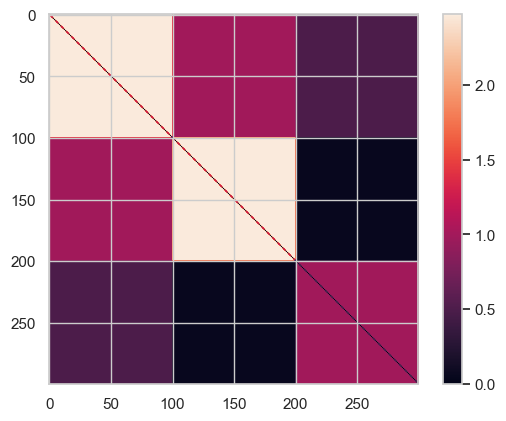

In [39]:
plt.imshow(graphon._get_edge_probabilities(300,False,True))
plt.colorbar()
plt.show()

In [40]:
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
n=300
rho_n=1/3
A = graphon.draw(rho = rho_n,n = n, exchangeable=False)

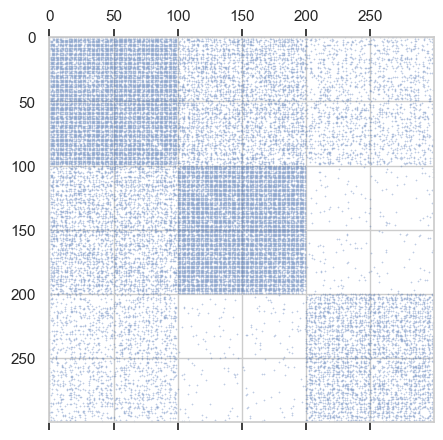

In [41]:
fig, ax = spy(A)#from pygraphon.plots.plot_matrices
plt.show()

In [42]:
edge_density(A)

0.33141583054626533

In [43]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
from pygraphon.estimators.MomentEstimator import MomentEstimator, SimpleMomentEstimator

In [44]:
hist = HistogramEstimator()
hist_epprox = hist.estimate(adjacency_matrix= A, bandwidthHist= None)
P = hist.estimated_edge_connectivity_matrix

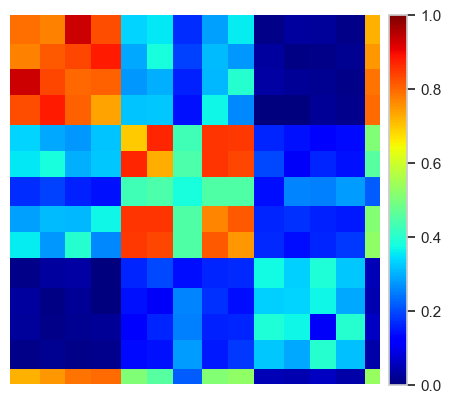

In [46]:
from pygraphon.plots.plots_graphon import plot_sample, plot
fig, ax = plt.subplots()
plot_sample(graphon = hist_epprox, fig = fig, ax = ax, colorbar= True, cmap = "jet")
plt.show()

In [277]:
hist_epprox.graphon.shape

(14, 14)

In [47]:
#from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
#counter = CycleCount(L = 9)
#momentestimator = SimpleMomentEstimator(3)
#mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)
#plot(mome_simple_approx)
#plt.show()
#mome_simple_approx.graphon
#mome_simple_approx.integral()

# Clustering the tiles independently (i.e. without structure)

In [282]:
from sklearn.cluster import KMeans
#Extract tiles and reshape
nrow_tile = hist_epprox.graphon.shape[0]
flat_graphon = hist_epprox.graphon[np.triu_indices(nrow_tile)]
nclust_detect_hist = len(np.unique(flat_graphon))

#Clustering according to kmeans
max_k = int(nrow_tile*(nrow_tile+1)/2)#number of individual tile
avr_graphon = np.asarray([flat_graphon.copy() for k in range(max_k)])#copies for different number of clusters
for i in range(nclust_detect_hist-1):
    if i==0:
        avr_graphon[i]=edge_density(A)*np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
        #Smooth using mean by memberhsip
        for j in range(i+1):#average tiles of same community
            avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()

In [49]:
#Reverse flattening back to 2d
KM_smooth_graphon = np.zeros((max_k,nrow_tile, nrow_tile))#initiate matrix containing smooth graphon
i,j = np.triu_indices(nrow_tile)
KM_smooth_graphon[:,i,j]=avr_graphon

In [50]:
#Make it symmetric by extracting diag, making it 3d and doing X+X^T-diag(X)
#Extract diagonal
i,j=np.diag_indices(nrow_tile)
diag_KM_vec=np.diagonal(KM_smooth_graphon, axis1=1,axis2=2)
#make 3d array with diagonal in axis 1&2
diag_km=np.zeros((max_k, nrow_tile,nrow_tile))
diag_km[:,i,j]=diag_KM_vec
#X+X^T-diag(X) on axis (1,2) of tensor
sym_KM_smooth_graphon= KM_smooth_graphon+np.transpose(KM_smooth_graphon, (0,2,1))-diag_km
sym_KM_smooth_graphon.shape

(105, 14, 14)

In [86]:
#Get smooth graphon into correct form and \hat{pij} for the whole tensor
smoothed_graphons = [StepGraphon(graphon=sym_KM_smooth_graphon[i], bandwidthHist=hist_epprox.bandwidthHist,
                                 initial_rho=hist_epprox.initial_rho) for i in range(sym_KM_smooth_graphon.shape[0])]

P_smooth = np.array([ g._get_edge_probabilities(n= 300, exchangeable= False) for g in smoothed_graphons ])

In [255]:
P_star_test = hist_epprox._get_edge_probabilities(300, False, True)
np.max(np.absolute((P_star_test-P_smooth[3])))#/(np.eye(P_star_test.shape[0])+P_star))

0.16305408174498137

# Evaluating the performance of our method

In [31]:
from experiment_smoothing import error_operator
from gen_sbm import AssociativeFullyRandom
from experiment_smoothing import smooth_hist

#Initialise parameters: n nodes, k blocks, theta prob
n_min, n_max, n_step = 60, 600, 20
n_list = np.arange(n_min, n_max, n_step)
rho_n = 1/3

k_max = 8
k_list = list(range(2, k_max+1))
theta_intra_min, theta_intra_max = 0.15, 0.5
theta_inter_min, theta_inter_max = 0.05, 0.1

#Create arrays to store metrics
hm_matrix_smoothing_test_error = np.zeros((n_list.shape[0], len(k_list)))
hm_matrix_smoothing_test_deviation_from_true = np.zeros_like(
    hm_matrix_smoothing_test_error)
hm_matrix_smoothing_test_deviation_from_hist = np.zeros_like(
    hm_matrix_smoothing_test_error)
hm_matrix_smoothing_test_comp_to_hist_perf = np.zeros_like(
    hm_matrix_smoothing_test_error)
metric_list = [hm_matrix_smoothing_test_comp_to_hist_perf,
               hm_matrix_smoothing_test_error,
               hm_matrix_smoothing_test_deviation_from_hist,
               hm_matrix_smoothing_test_deviation_from_true]

#Initialise connectivity matrices for different prior to nested loop
#to store them and analyse them separately
theta =[]
for j, k in enumerate(k_list):
    theta.append(AssociativeFullyRandom(K=k,
                                   min_inside_classes=theta_intra_min,
                                   max_inside_classes=theta_intra_max,
                                   min_outside_classes=theta_inter_min,
                                   max_outside_classes=theta_inter_max).Theta)

In [32]:
for j, k in enumerate(k_list):
    print(f"Performing k = {k}")
    for i, n_it in enumerate(n_list):
        _, _, rel_error = smooth_hist(n = n_it, bandwidth= 1/k, rho_n=rho_n, graphon_matrix = theta[j])
        metric_list = error_operator(rel_error, metric_list, i,j,k)

Performing k = 2
Performing k = 3
Performing k = 4


KeyboardInterrupt: 

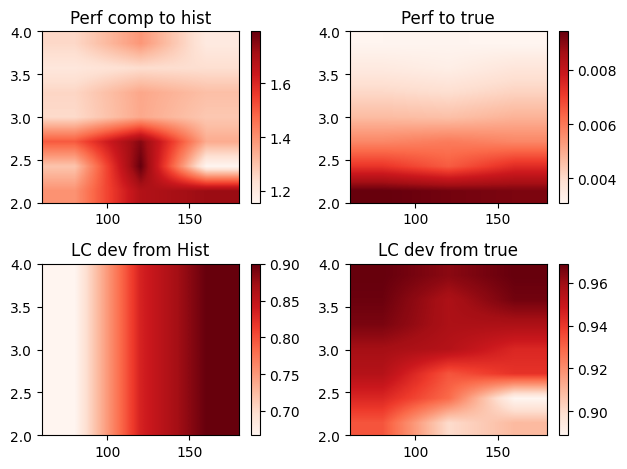

(1, 2)


1.155404254687862

In [28]:
from experiment_smoothing import smooth_heatmap
from experiment_smoothing import smooth_heatmap2
title_list = ('Perf comp to hist', 'Perf to true', 'LC dev from Hist',
              'LC dev from true')
tile_type = 'bilinear'
smooth_heatmap2(n_list, k_list, metric_list, title_list, tile_type)
print(np.unravel_index(metric_list[0].argmin(), metric_list[3].shape))
metric_list[0][np.unravel_index(metric_list[0].argmin(), metric_list[3].shape)]

In [ ]:
data_test = np.load('data.npy')